In [59]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from utils import *

import Orange
from orangecontrib.spectroscopy import data
from orangecontrib.spectroscopy.data import getx
from Orange.data.io import FileFormat

#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [3]:
#Orange.data.Table('MEC_02_115_CR_N_01_20240319.ptir')

In [4]:
absolute_filename = FileFormat.locate('mgstearate_20240409.ptir')
#absolute_filename = FileFormat.locate('MEC_02_115_CR_N_01_20240319.ptir')
reader = FileFormat.get_reader(absolute_filename)
sheet = 'OPTIR (mV)'
reader.select_sheet(sheet)
spectra = read_spectra(reader)

spectra_data = pd.DataFrame(spectra[1])
coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
spectra_data = spectra_data.reset_index(drop=True)
spectra_data.columns = spectra[0]

#spectra_data = pd.concat([spectra_data, coords],axis=1)
spectra_data.to_csv('mgstearate_ir_20240409.csv')

absolute_filename = FileFormat.locate('mgstearate_20240409.ptir')
#absolute_filename = FileFormat.locate('MEC_02_115_CR_N_01_20240319.ptir')
reader = FileFormat.get_reader(absolute_filename)
sheet = 'Raman Intensity'
reader.select_sheet(sheet)
spectra = read_spectra(reader)

spectra_data = pd.DataFrame(spectra[1])
coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
spectra_data = spectra_data.reset_index(drop=True)
spectra_data.columns = spectra[0]

#spectra_data = pd.concat([spectra_data, coords],axis=1)
spectra_data.to_csv('mgstearate_raman_20240409.csv')



In [5]:
path = '../MEC_02_115/Raw Data/'
dirs = os.listdir(path)

#for i in np.where([d[-4:] == 'ptir' for d in dirs])[0]:
#    print(i)
#    del dirs[i]

for d in dirs:
    if d[-4:] == 'ptir' or d==".DS_Store":
        del dirs[np.where(np.array(dirs) == d)[0][0]]

In [6]:
files_list = []
for d in dirs:
    files = os.listdir(path + d)
    files_list = files_list + [d+'/'+f for f in files if f[-5:] == '.ptir']
    #print([f for f in files if f[-5:] == '.ptir'])

In [7]:
files_codes = pd.merge(pd.DataFrame({'file_name':files_list,
                                     'key':[str(x[:2]) for x in files_list],
                                     'run':[str(x[5:7]) if len(x) == 40 
                                            else str(x[6:8]) for x in files_list],
                                     'day':[str(x[-9:-5]) for x in files_list],
                                     'material':[str(x[3:4]) if str(x[:2]) != "Bl" 
                                                 else "-" for x in files_list]}),
                       pd.DataFrame({'key':np.unique([str(x[:2]) for x in files_list]),
                                     'brand':['Blank', 'CR', 'FB', 'KC', 'MF']}))
files_codes = files_codes.set_index('file_name')
files_codes

,key,run,day,material,brand
file_name,,,,,
MF_L_01/MEC_02_115_MF_L_01_20240514.ptir,MF,01,0514,L,MF
MF_N_02/MEC_02_115_MF_N_02_20240409.ptir,MF,02,0409,N,MF
MF_L_02/MEC_02_115_MF_L_02_20240515.ptir,MF,02,0515,L,MF
MF_N_01/MEC_02_115_MF_N_01_20240405.ptir,MF,01,0405,N,MF
CR_N_01/MEC_02_115_CR_N_01_20240319.ptir,CR,01,0319,N,CR
CR_N_02/MEC_02_115_CR_N_02_20240326.ptir,CR,02,0326,N,CR
CR_N_02/MEC_02_115_CR_N_02_20240319.ptir,CR,02,0319,N,CR
KC_L_02/MEC_02_115_KC_L_02_20240425.ptir,KC,02,0425,L,KC
KC_N_01/MEC_02_115_KC_N_01_20240321.ptir,KC,01,0321,N,KC


In [8]:
files_list

['MF_L_01/MEC_02_115_MF_L_01_20240514.ptir',
 'CR_N_01/MEC_02_115_CR_N_01_20240319.ptir',
 'KC_L_02/MEC_02_115_KC_L_02_20240425.ptir',
 'FB_L_01/MEC_02_115_FB_L_01_20240411.ptir',
 'FB_N_02/MEC_02_115_FB_N_02_20240404.ptir',
 'KC_N_01/MEC_02_115_KC_N_01_20240321.ptir',
 'MF_N_02/MEC_02_115_MF_N_02_20240409.ptir',
 'Blank_02/MEC_02_115_Blank_02_20240521.ptir',
 'KC_L_01/MEC_02_115_KC_L_01_20240423.ptir',
 'CR_N_02/MEC_02_115_CR_N_02_20240326.ptir',
 'CR_N_02/MEC_02_115_CR_N_02_20240319.ptir',
 'MF_L_02/MEC_02_115_MF_L_02_20240515.ptir',
 'FB_L_02/MEC_02_115_FB_L_02_20240411.ptir',
 'FB_L_02/MEC_02_115_FB_L_02_20240416.ptir',
 'FB_N_01/MEC_02_115_FB_N_01_20240328.ptir',
 'MF_N_01/MEC_02_115_MF_N_01_20240405.ptir',
 'Blank_01/MEC_02_115_Blank_01_20240521.ptir',
 'KC_N_02/MEC_02_115_KC_N_02_20240326.ptir',
 'KC_N_02/MEC_02_115_KC_N_02_20240328.ptir']

In [82]:

absolute_filename = FileFormat.locate('../../../../conformal-hqi/new_ptir_data/MEC_04_006_1-5um_PP_20240618.ptir')

reader = FileFormat.get_reader(absolute_filename)
sheet = 'OPTIR (mV)'
reader.select_sheet(sheet)
spectra = read_spectra(reader)

spectra_data_PP = pd.DataFrame(spectra[1])

spectra_data_PP = spectra_data_PP.reset_index(drop=True)
spectra_data_PP = spectra_data_PP.reset_index()
spectra_data_PP.columns = ['id'] + list(spectra[0])
spectra_data_PP['id'] = ['5um_PP_' + str(i+1) for i in range(spectra_data_PP.shape[0])]

In [83]:

absolute_filename = FileFormat.locate('../../../../conformal-hqi/new_ptir_data/MEC_04_007_3-16um_LDPE_20240618.ptir')

reader = FileFormat.get_reader(absolute_filename)
sheet = 'OPTIR (mV)'
reader.select_sheet(sheet)
spectra = read_spectra(reader)

spectra_data_LDPE = pd.DataFrame(spectra[1])

spectra_data_LDPE = spectra_data_LDPE.reset_index(drop=True)
spectra_data_LDPE = spectra_data_LDPE.reset_index()
spectra_data_LDPE.columns = ['id'] + list(spectra[0])
spectra_data_LDPE['id'] = ['16um_LDPE_' + str(i+1) for i in range(spectra_data_LDPE.shape[0])]

In [85]:
spectra_data = pd.concat([spectra_data_PP, spectra_data_LDPE], axis=0).reset_index(drop=True)
spectra_data.to_csv('../../../../conformal-hqi/data/data_PTIR.csv')

In [55]:
spectra_list = []

for f in files_list:
    absolute_filename = FileFormat.locate(path + f)
    #absolute_filename = FileFormat.locate('MEC_02_115_CR_N_01_20240319.ptir')
    reader = FileFormat.get_reader(absolute_filename)
    sheet = 'OPTIR (mV)'
    reader.select_sheet(sheet)
    spectra = read_spectra(reader)

    spectra_data = pd.DataFrame(spectra[1])
    coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0]
    
    #spectra_data['id'] = f[:-5]
    spectra_data['id'] = [f[:-5]+'_'+str(i) for i in range(spectra_data.shape[0])] 
    spectra_data = pd.concat([spectra_data, coords],axis=1)
    spectra_list.append(spectra_data)    

#spectra_list
spectra_ir_df = pd.concat(spectra_list)
spectra_ir_df.to_csv('MEC_02_115_ir_raw.csv')

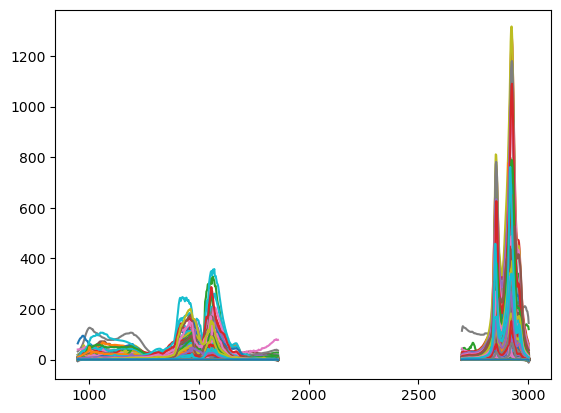

In [56]:
_ = plt.plot(spectra_ir_df.iloc[:,:-3].T)

In [57]:
spectra_list = []
wavenumbers = []
mean_intensity_list = []
adjusted_files = []

for f in files_list:


    absolute_filename = FileFormat.locate(path + f)
    reader = FileFormat.get_reader(absolute_filename)
    sheet = 'Raman Intensity'
    reader.select_sheet(sheet)
    spectra = read_spectra(reader)

    spectra_data = pd.DataFrame(spectra[1])
    mean_intensity_list = mean_intensity_list + list(spectra_data.mean(1))
    coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0] 
    
    #spectra_data['id'] = f[:-5]
    spectra_data['id'] = [f[:-5]+'_'+str(i) for i in range(spectra_data.shape[0])] 
    
    spectra_data_long = spectra_data.melt(id_vars='id')#
    spectra_data_long.iloc[:,1:] = spectra_data_long.iloc[:,1:].astype('float32')

    spectra_data_long.columns = ['id','wavelength','intensity']
    spectra_data_long['polymer'] = ''

    spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=326.122151, max_wl=3877.587228, n=1027, id_spetr='id')
    spectra_data_int = spectra_data_long_int.pivot(
                index=['id'], 
                columns='wavelength', 
                values='intensity').reset_index()
    spectra_data_int
    
    
    spectra_data = pd.concat([spectra_data_int, coords],axis=1)
    spectra_list.append(spectra_data)    

spectra_ir_df = pd.concat(spectra_list)
spectra_ir_df.to_csv('MEC_02_115_raman_raw.csv')

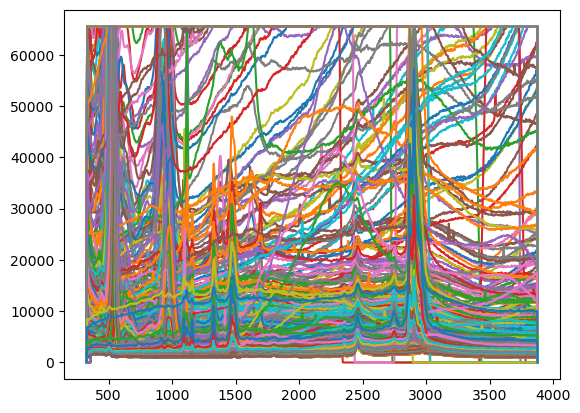

In [58]:
_ = plt.plot(spectra_ir_df.iloc[:,1:-2].T)